<a href="https://colab.research.google.com/github/bgeethagayathri2-del/House-price-prediction/blob/main/House_price.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Linear Regression
  R2 score: 0.576
  Mean absolute error: 0.533
Random Forest
  R2 score: 0.805
  Mean absolute error: 0.328


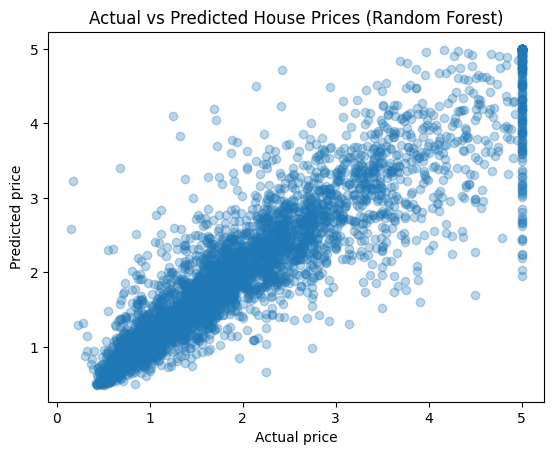

MedInc 0.525
AveOccup 0.138
Latitude 0.089
Longitude 0.089
HouseAge 0.055
AveRooms 0.044
Population 0.031
AveBedrms 0.03


In [1]:
# House Price Prediction: Linear Regression vs Random Forest
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error
import matplotlib.pyplot as plt

# 1. Load data (prices are in units of $100,000)
data = fetch_california_housing()
X, y = data.data, data.target

# 2. Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Train two models
lr = LinearRegression()
lr.fit(X_train, y_train)
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# 4. Compare
for name, model in [("Linear Regression", lr), ("Random Forest", rf)]:
    pred = model.predict(X_test)
    print(name)
    print("  R2 score:", round(r2_score(y_test, pred), 3))
    print("  Mean absolute error:", round(mean_absolute_error(y_test, pred), 3))

# 5. Graph: actual vs predicted prices (Random Forest)
plt.scatter(y_test, rf.predict(X_test), alpha=0.3)
plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.title("Actual vs Predicted House Prices (Random Forest)")
plt.show()

# 6. Which features matter most?
for feature, score in sorted(zip(data.feature_names, rf.feature_importances_),
                             key=lambda x: -x[1]):
    print(feature, round(score, 3))